# AI Lab Experiment 1

## Data Preprocessing Using Python (Pandas)

**Name:** Fathima Fasila M

**Semester:** V

**Course:** Artificial Intelligence Lab

**Experiment:** Data Preprocessing

**Dataset:** Football Player Performance Dataset

In [24]:
!pip install imbalanced-learn

In [2]:
from google.colab import files

uploaded = files.upload()

Saving fifa.sample.csv to fifa.sample.csv


## Step 1: Import Libraries and Load Dataset

This step imports the required Python libraries and loads the football player performance dataset into a Pandas DataFrame.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Load Dataset
df = pd.read_csv("fifa.sample.csv")

print("Dataset Loaded Successfully!")

display(df.head())

print("\nShape :", df.shape)

Dataset Loaded Successfully!


,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,preferred_foot,...,possession_impact,pressure_resistance,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating
0,P00055,Rodri Fati,26,Spanish,Spain,3,Goalkeeper,195,75,Left,...,1.1,44.2,55.9,42.0,51.8,0,0,242,0,5.8
1,P00070,Ansu Le Normand,19,Spanish,Spain,18,Midfielder,178,75,Right,...,3.5,38.2,43.7,31.1,52.7,0,3,342,0,5.5
2,P00066,Gavi Ramos,18,Spanish,Spain,14,Midfielder,177,72,Left,...,15.3,99.0,99.0,83.4,54.8,1,1,245,0,8.4
3,P00073,Pedro Cubarsi,20,Spanish,Spain,21,Forward,182,74,Right,...,1.2,19.8,42.3,40.9,78.5,5,3,422,0,6.7
4,P00059,Alvaro Oyarzabal,23,Spanish,Spain,7,Defender,191,81,Left,...,6.2,44.1,33.5,60.0,56.6,0,0,440,0,5.7



Shape : (54600, 75)


## Step 2: Explore Dataset Information

This step displays the number of rows, columns, data types and checks for missing values in the dataset.

In [27]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

print("\nDataset Information")

df.info()

print("\nMissing Values")

display(df.isnull().sum())

Rows : 54600
Columns : 75

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54600 entries, 0 to 54599
Data columns (total 75 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   player_id                 54600 non-null  object 
 1   player_name               54600 non-null  object 
 2   age                       54600 non-null  int64  
 3   nationality               54600 non-null  object 
 4   team                      54600 non-null  object 
 5   jersey_number             54600 non-null  int64  
 6   position                  54600 non-null  object 
 7   height_cm                 54600 non-null  int64  
 8   weight_kg                 54600 non-null  int64  
 9   preferred_foot            54600 non-null  object 
 10  club_name                 54600 non-null  object 
 11  market_value_eur          54600 non-null  int64  
 12  match_id                  54600 non-null  object 
 13  match_date    

,0
player_id,0
player_name,0
age,0
nationality,0
team,0
...,...
total_goals_tournament,0
total_assists_tournament,0
total_minutes_tournament,0
player_of_match_awards,0


## Step 3: Exploratory Data Inspection

This step displays the first, last and randomly selected records to understand the dataset structure.

In [28]:
print("First 5 Rows")

display(df.head())

print("Last 5 Rows")

display(df.tail())

print("Random 5 Rows")

display(df.sample(5, random_state=42))

First 5 Rows


,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,preferred_foot,...,possession_impact,pressure_resistance,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating
0,P00055,Rodri Fati,26,Spanish,Spain,3,Goalkeeper,195,75,Left,...,1.1,44.2,55.9,42.0,51.8,0,0,242,0,5.8
1,P00070,Ansu Le Normand,19,Spanish,Spain,18,Midfielder,178,75,Right,...,3.5,38.2,43.7,31.1,52.7,0,3,342,0,5.5
2,P00066,Gavi Ramos,18,Spanish,Spain,14,Midfielder,177,72,Left,...,15.3,99.0,99.0,83.4,54.8,1,1,245,0,8.4
3,P00073,Pedro Cubarsi,20,Spanish,Spain,21,Forward,182,74,Right,...,1.2,19.8,42.3,40.9,78.5,5,3,422,0,6.7
4,P00059,Alvaro Oyarzabal,23,Spanish,Spain,7,Defender,191,81,Left,...,6.2,44.1,33.5,60.0,56.6,0,0,440,0,5.7


Last 5 Rows


,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,preferred_foot,...,possession_impact,pressure_resistance,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating
54595,P00996,Amir Younis,28,Iraqi,Iraq,8,Defender,177,73,Right,...,0.0,41.9,27.7,31.3,40.5,1,0,97,0,0.0
54596,P01006,Safaa Al-Khafaji,20,Iraqi,Iraq,18,Midfielder,176,72,Right,...,0.0,64.2,53.1,64.8,64.3,2,0,206,0,0.0
54597,P01008,Ahmed Hussein,26,Iraqi,Iraq,20,Midfielder,173,77,Left,...,0.0,75.4,55.0,65.0,64.5,1,1,359,0,0.0
54598,P00991,Ibrahim Mhawi,30,Iraqi,Iraq,3,Goalkeeper,190,81,Right,...,0.0,96.3,39.6,99.0,99.0,0,0,342,0,0.0
54599,P00989,Mohannad Hussein,27,Iraqi,Iraq,1,Goalkeeper,187,73,Right,...,0.0,99.0,34.1,99.0,99.0,0,0,286,0,0.0


Random 5 Rows


,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,preferred_foot,...,possession_impact,pressure_resistance,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating
45140,P00576,Luis Araujo,30,Uruguayan,Uruguay,4,Defender,179,75,Left,...,7.0,71.3,40.0,63.0,61.2,0,0,146,0,5.4
29111,P00979,Dostonbek Kenjayev,24,Uzbek,Uzbekistan,17,Midfielder,179,78,Right,...,0.0,24.2,26.9,45.0,43.7,1,0,170,0,0.0
44821,P00742,Joel Soto,26,Costa Rican,Costa Rica,14,Midfielder,179,71,Left,...,0.0,60.4,63.0,60.8,30.5,0,1,157,0,0.0
38375,P00625,Paolo Lapadula,30,Peruvian,Peru,1,Goalkeeper,180,71,Right,...,0.0,56.4,29.1,80.9,51.0,0,0,362,0,0.0
6788,P01165,Wahbi Chalali,24,Tunisian,Tunisia,21,Forward,185,74,Right,...,4.6,76.4,59.4,86.5,80.8,3,0,349,0,5.4


## Step 4: Handle Missing Values

Missing values are detected and replaced using the median for numerical columns and the mode for categorical columns.

In [29]:
print("Missing Values Before")

display(df.isnull().sum())

# Numeric Columns
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# Categorical Columns
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing Values After")

display(df.isnull().sum())

Missing Values Before


,0
player_id,0
player_name,0
age,0
nationality,0
team,0
...,...
total_goals_tournament,0
total_assists_tournament,0
total_minutes_tournament,0
player_of_match_awards,0



Missing Values After


,0
player_id,0
player_name,0
age,0
nationality,0
team,0
...,...
total_goals_tournament,0
total_assists_tournament,0
total_minutes_tournament,0
player_of_match_awards,0


## Step 5: Detect and Remove Duplicate Records

Duplicate rows are identified and removed from the dataset.

In [30]:
print("Duplicate Rows Before :", df.duplicated().sum())

df.drop_duplicates(inplace=True)

print("Duplicate Rows After :", df.duplicated().sum())

Duplicate Rows Before : 0
Duplicate Rows After : 0


## Step 6: Detect Outliers

Outliers are detected using box plots for important numerical attributes.

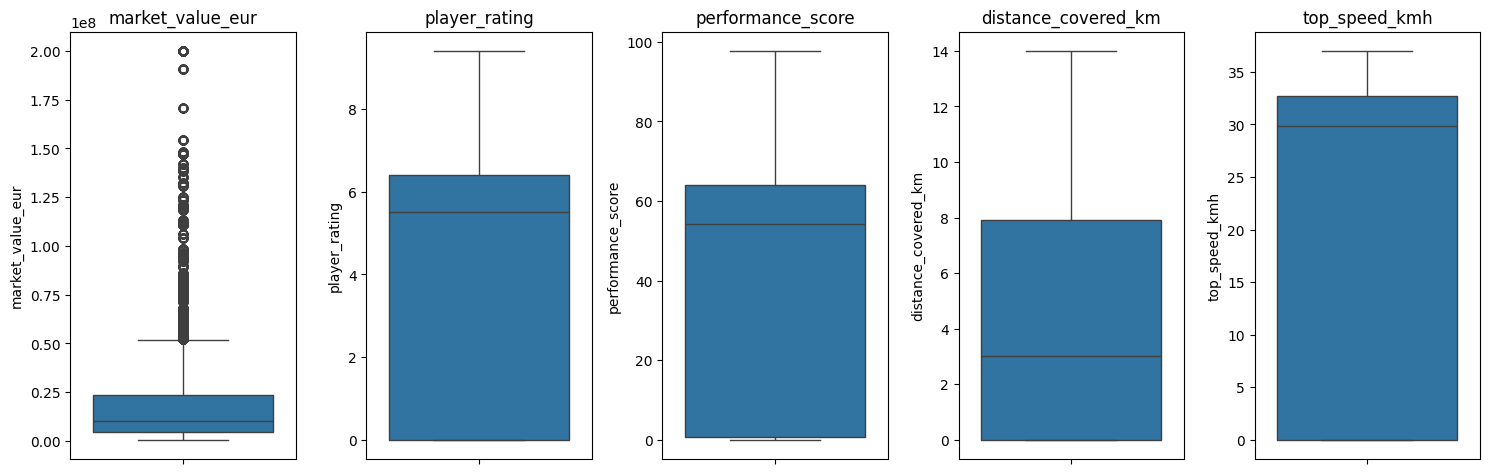

In [31]:
important_cols = [

    "market_value_eur",

    "player_rating",

    "performance_score",

    "distance_covered_km",

    "top_speed_kmh"

]

plt.figure(figsize=(15,5))

for i,col in enumerate(important_cols):

    plt.subplot(1,5,i+1)

    sns.boxplot(y=df[col])

    plt.title(col)

plt.tight_layout()

plt.show()

## Step 7: Handle Outliers

Outliers are handled using the IQR clipping technique.

In [32]:
for col in important_cols:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3-Q1

    lower = Q1-1.5*IQR

    upper = Q3+1.5*IQR

    df[col]=df[col].clip(lower,upper)

print("Outliers handled successfully.")

Outliers handled successfully.


## Step 8: Data Cleaning and Encoding

Categorical variables are cleaned and converted into numerical format using Label Encoding and One-Hot Encoding.

In [33]:
# Remove spaces

text_cols=df.select_dtypes(include="object").columns

for col in text_cols:

    df[col]=df[col].str.strip()

# Standardize text

df["preferred_foot"]=df["preferred_foot"].str.title()

df["position"]=df["position"].str.title()

# Label Encoding

le=LabelEncoder()

df["position_encoded"]=le.fit_transform(df["position"])

# One Hot Encoding

df=pd.get_dummies(

    df,

    columns=["preferred_foot"],

    dtype=int

)

display(df.head())

,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,club_name,...,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating,position_encoded,preferred_foot_Left,preferred_foot_Right
0,P00055,Rodri Fati,26,Spanish,Spain,3,Goalkeeper,195,75,RB Salzburg,...,42.0,51.8,0,0,242,0,5.8,2,1,0
1,P00070,Ansu Le Normand,19,Spanish,Spain,18,Midfielder,178,75,Chelsea,...,31.1,52.7,0,3,342,0,5.5,3,0,1
2,P00066,Gavi Ramos,18,Spanish,Spain,14,Midfielder,177,72,AIK,...,83.4,54.8,1,1,245,0,8.4,3,1,0
3,P00073,Pedro Cubarsi,20,Spanish,Spain,21,Forward,182,74,PSV Eindhoven,...,40.9,78.5,5,3,422,0,6.7,1,0,1
4,P00059,Alvaro Oyarzabal,23,Spanish,Spain,7,Defender,191,81,Juventus,...,60.0,56.6,0,0,440,0,5.7,0,1,0


## Step 9: Feature Scaling

Min-Max Normalization and Standardization are applied to numerical features.

In [34]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Select only numerical columns
numeric_cols = df.select_dtypes(include=['number']).columns

# Remove target columns (don't scale them)
exclude_cols = ["performance_score", "tournament_rating"]

scale_cols = [col for col in numeric_cols if col not in exclude_cols]

# ---------- Min-Max Scaling ----------
minmax_scaler = MinMaxScaler()

df_minmax = df.copy()

df_minmax[scale_cols] = minmax_scaler.fit_transform(df[scale_cols])

print("Min-Max Scaling Completed")

display(df_minmax[scale_cols].head())

# ---------- Standardization ----------
standard_scaler = StandardScaler()

df_standard = df.copy()

df_standard[scale_cols] = standard_scaler.fit_transform(df[scale_cols])

print("\nStandardization Completed")

display(df_standard[scale_cols].head())

Min-Max Scaling Completed


,age,jersey_number,height_cm,weight_kg,market_value_eur,goals_team,goals_opponent,minutes_played,goals,assists,...,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,position_encoded,preferred_foot_Left,preferred_foot_Right
0,0.409091,0.08,0.864865,0.454545,0.075087,0.142857,0.0,0.800000,0.00,0.000000,...,0.541489,0.229730,0.438095,0.0,0.000,0.393496,0.0,0.666667,1.0,0.0
1,0.090909,0.68,0.405405,0.454545,0.085487,0.142857,0.0,1.000000,0.00,0.000000,...,0.411702,0.082432,0.448810,0.0,0.375,0.556098,0.0,1.000000,0.0,1.0
2,0.045455,0.52,0.378378,0.318182,1.000000,0.142857,0.0,0.811111,0.25,0.000000,...,1.000000,0.789189,0.473810,0.1,0.125,0.398374,0.0,1.000000,1.0,0.0
3,0.136364,0.80,0.513514,0.409091,0.219586,0.142857,0.0,0.888889,0.25,0.333333,...,0.396809,0.214865,0.755952,0.5,0.375,0.686179,0.0,0.333333,0.0,1.0
4,0.272727,0.24,0.756757,0.727273,0.249178,0.142857,0.0,0.877778,0.00,0.000000,...,0.303191,0.472973,0.495238,0.0,0.000,0.715447,0.0,0.000000,1.0,0.0



Standardization Completed


,age,jersey_number,height_cm,weight_kg,market_value_eur,goals_team,goals_opponent,minutes_played,goals,assists,...,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,position_encoded,preferred_foot_Left,preferred_foot_Right
0,-0.072891,-1.400000,2.125872,-0.191032,-0.764372,-0.287921,-1.15915,0.982997,-0.219869,-0.219073,...,0.435434,-1.095195,-0.276121,-0.588782,-0.652269,-0.259409,-0.148458,0.495188,1.707531,-1.707531
1,-1.793858,0.600000,-0.582111,-0.191032,-0.730730,-0.287921,-1.15915,1.477239,-0.219869,-0.219073,...,-0.108623,-1.644041,-0.210241,-0.588782,2.568280,0.596718,-0.148458,1.299867,-0.585641,0.585641
2,-2.039710,0.066667,-0.741404,-0.950248,2.227793,-0.287921,-1.15915,1.010455,3.749989,-0.219073,...,2.357470,0.989414,-0.056522,0.325486,0.421247,-0.233725,-0.148458,1.299867,1.707531,-1.707531
3,-1.548005,1.000000,0.055061,-0.444104,-0.296908,-0.287921,-1.15915,1.202660,3.749989,3.964699,...,-0.171056,-1.150583,1.678316,3.982558,2.568280,1.281619,-0.148458,-0.309492,-0.585641,0.585641
4,-0.810448,-0.866667,1.488699,1.327400,-0.201177,-0.287921,-1.15915,1.175202,-0.219869,-0.219073,...,-0.563490,-0.188843,0.075238,-0.588782,-0.652269,1.435722,-0.148458,-1.114172,1.707531,-1.707531


## Step 10: Feature Selection

Correlation analysis is performed to identify features that are highly related to the performance score.

In [35]:
# Correlation with Performance Score

correlation = df.select_dtypes(include='number').corr()

performance_corr = correlation["performance_score"].sort_values(ascending=False)

print("Features Most Related to Performance Score\n")

display(performance_corr)

Features Most Related to Performance Score



,performance_score
performance_score,1.000000
player_rating,0.996610
tournament_rating,0.993943
top_speed_kmh,0.975388
distance_covered_km,0.833653
...,...
position_encoded,-0.024684
penalty_saves,-0.032103
age,-0.038799
weight_kg,-0.046869


## Step 11: Correlation Matrix and Heatmap

A heatmap is generated to visualize the relationship among important numerical features.

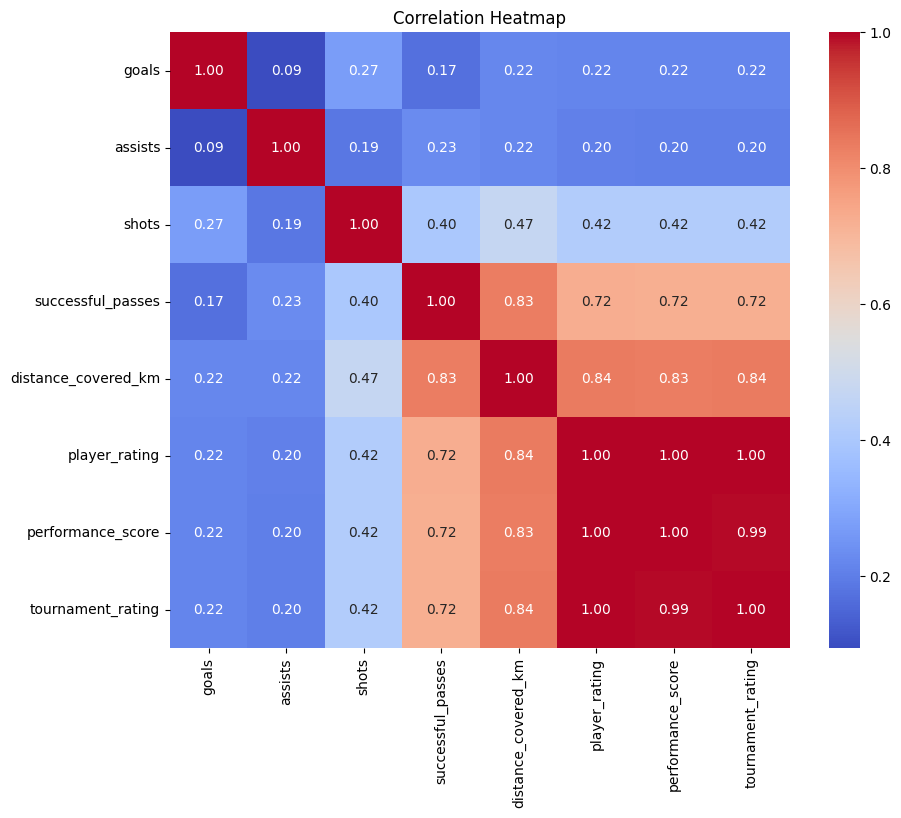

In [36]:
selected_features = [

    "goals",

    "assists",

    "shots",

    "successful_passes",

    "distance_covered_km",

    "player_rating",

    "performance_score",

    "tournament_rating"

]

plt.figure(figsize=(10,8))

sns.heatmap(

    df[selected_features].corr(),

    annot=True,

    cmap="coolwarm",

    fmt=".2f"

)

plt.title("Correlation Heatmap")

plt.show()

## Step 12: Feature Engineering

New features such as Goal Contribution, Shot Accuracy and Pass Success Rate are created.

In [37]:
# Goal Contribution

df["goal_contribution"] = df["goals"] + df["assists"]

# Shot Accuracy

df["shot_accuracy"] = np.where(

    df["shots"] > 0,

    df["shots_on_target"] / df["shots"],

    0

)

# Pass Success Rate

df["pass_success_rate"] = np.where(

    df["total_passes"] > 0,

    df["successful_passes"] / df["total_passes"],

    0

)

# Defensive Contribution

df["defensive_contribution_total"] = (

    df["tackles"]

    + df["interceptions"]

    + df["clearances"]

)

print("New Features Created Successfully!")

display(df[[
    "goal_contribution",
    "shot_accuracy",
    "pass_success_rate",
    "defensive_contribution_total"
]].head())

New Features Created Successfully!


,goal_contribution,shot_accuracy,pass_success_rate,defensive_contribution_total
0,0,0.0,0.576923,0
1,0,0.0,0.875000,4
2,1,0.0,0.847059,2
3,2,0.4,0.631579,3
4,0,0.0,0.750000,4


## Step 13: Data Type Conversion

Columns are converted into appropriate data types such as datetime and float.

In [38]:
# Convert Match Date

df["match_date"] = pd.to_datetime(

    df["match_date"],

    format="%d-%m-%Y"

)

# Convert Market Value to float

df["market_value_eur"] = df["market_value_eur"].astype(float)

print(df.dtypes)

player_id                        object
player_name                      object
age                               int64
nationality                      object
team                             object
                                 ...   
preferred_foot_Right              int64
goal_contribution                 int64
shot_accuracy                   float64
pass_success_rate               float64
defensive_contribution_total      int64
Length: 81, dtype: object


## Step 14: Handle Inconsistent Data

Text data is cleaned by removing extra spaces and converting values into a consistent format.

In [39]:
# Remove Extra Spaces

text_columns = df.select_dtypes(include="object").columns

for col in text_columns:

    df[col] = df[col].str.strip()

# Convert text to Title Case

if "position" in df.columns:
    df["position"] = df["position"].str.title()

if "team" in df.columns:
    df["team"] = df["team"].str.title()

if "club_name" in df.columns:
    df["club_name"] = df["club_name"].str.title()

print("Text Cleaning Completed Successfully!")

display(df.head())

Text Cleaning Completed Successfully!


,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,club_name,...,total_minutes_tournament,player_of_match_awards,tournament_rating,position_encoded,preferred_foot_Left,preferred_foot_Right,goal_contribution,shot_accuracy,pass_success_rate,defensive_contribution_total
0,P00055,Rodri Fati,26,Spanish,Spain,3,Goalkeeper,195,75,Rb Salzburg,...,242,0,5.8,2,1,0,0,0.0,0.576923,0
1,P00070,Ansu Le Normand,19,Spanish,Spain,18,Midfielder,178,75,Chelsea,...,342,0,5.5,3,0,1,0,0.0,0.875000,4
2,P00066,Gavi Ramos,18,Spanish,Spain,14,Midfielder,177,72,Aik,...,245,0,8.4,3,1,0,1,0.0,0.847059,2
3,P00073,Pedro Cubarsi,20,Spanish,Spain,21,Forward,182,74,Psv Eindhoven,...,422,0,6.7,1,0,1,2,0.4,0.631579,3
4,P00059,Alvaro Oyarzabal,23,Spanish,Spain,7,Defender,191,81,Juventus,...,440,0,5.7,0,1,0,0,0.0,0.750000,4


## Step 15: Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio.

In [40]:
from sklearn.model_selection import train_test_split

# Features (X)
X = df.select_dtypes(include=['number']).drop(columns=["performance_score"])

# Target (y)
y = df["performance_score"]

# Train-Test Split (80% Train, 20% Test)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)
print("Training Target :", y_train.shape)
print("Testing Target :", y_test.shape)

Training Features : (43680, 67)
Testing Features : (10920, 67)
Training Target : (43680,)
Testing Target : (10920,)


## Step 16: Data Balancing

SMOTE is used to balance the dataset by generating synthetic samples for the minority class.

In [41]:
from imblearn.over_sampling import SMOTE

# Create two classes using median
y_class = (df["performance_score"] >= df["performance_score"].median()).astype(int)

# Features
X = df.select_dtypes(include=['number']).drop(columns=["performance_score"])

print("Before Balancing")

print(y_class.value_counts())

# Apply SMOTE

smote = SMOTE(random_state=42)

X_balanced, y_balanced = smote.fit_resample(X, y_class)

print("\nAfter Balancing")

print(pd.Series(y_balanced).value_counts())

Before Balancing
performance_score
1    27346
0    27254
Name: count, dtype: int64

After Balancing
performance_score
0    27346
1    27346
Name: count, dtype: int64


## Step 17: Visualization

The distribution of player ratings is visualized before and after feature scaling.

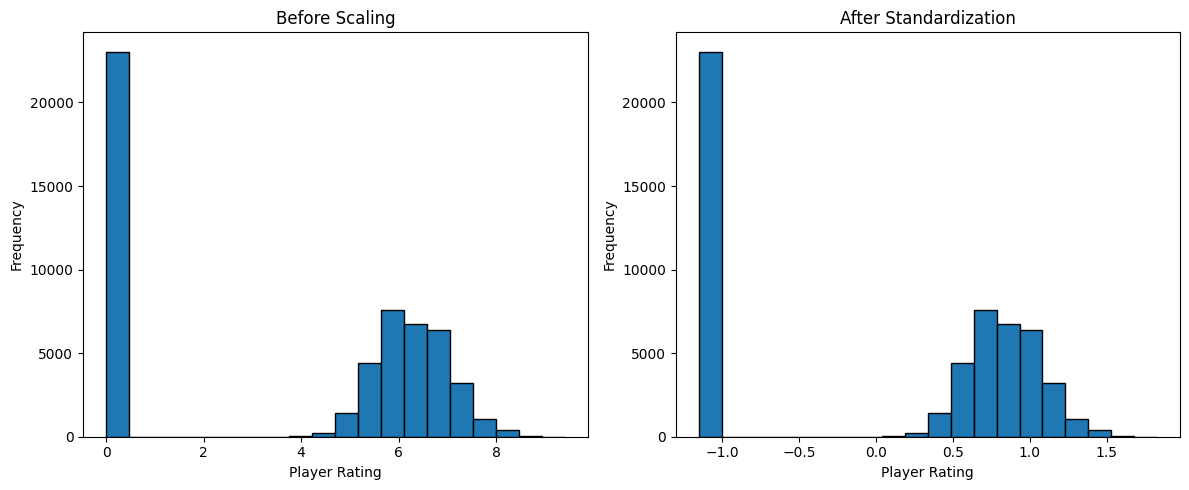

In [42]:
plt.figure(figsize=(12,5))

# Before Scaling

plt.subplot(1,2,1)

plt.hist(df["player_rating"], bins=20, edgecolor='black')

plt.title("Before Scaling")

plt.xlabel("Player Rating")

plt.ylabel("Frequency")

# After Scaling

plt.subplot(1,2,2)

plt.hist(df_standard["player_rating"], bins=20, edgecolor='black')

plt.title("After Standardization")

plt.xlabel("Player Rating")

plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

## Step 18: Compare Dataset

The cleaned dataset is summarized by comparing rows, columns, missing values and duplicates.

In [43]:
comparison = pd.DataFrame({

    "Property":[
        "Rows",
        "Columns",
        "Missing Values",
        "Duplicate Rows"
    ],

    "Value":[
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]

})

print("Dataset Summary After Preprocessing")

display(comparison)

Dataset Summary After Preprocessing


,Property,Value
0,Rows,54600
1,Columns,81
2,Missing Values,0
3,Duplicate Rows,0


## Step 19: Save Cleaned Dataset

The cleaned and preprocessed dataset is saved as a new CSV file for future use.

In [45]:
df.to_csv("football_players_cleaned.csv", index=False)

print(" Cleaned Dataset Saved Successfully!")

print("Filename : football_players_cleaned.csv")

 Cleaned Dataset Saved Successfully!
Filename : football_players_cleaned.csv
